# Trabajo Práctico de Laboratorio Nº 9: Resistencias de Bajo Valor

## Datos del grupo

* **Curso:** R4052
* **Nº de Grupo:** 2
* **Integrantes:**
  1.   Paul Leandro Encinas Claros
  2.   Franco Ezequiel Ferrario
  3.   Matías Sebastián Marchesi
  4.   Bruno Quiroga

  


# Inicialización

Se deja un bloque de código para la inicialización de las funciones e imports de bibliotecas necesarias.

In [1]:
# Librerías de Python a utilizar
import numpy as np
import math
import IPython
from IPython.display import display, Math
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Funciones Auxiliares para cálculo de Incertidumbre y Formateo
def incert_A(mediciones):
    s = np.std(mediciones, ddof=1)
    return s / math.sqrt(len(mediciones))

def incert_B(err_rel, nd, res, valor):
    # Incertidumbre tipo B asumiendo distribución rectangular
    err_limite = (err_rel / 100) * abs(valor) + nd * res
    return err_limite / math.sqrt(3)

def incert_combinada(uA, uB):
    return math.sqrt(uA**2 + uB**2)

def incert_expandida(uC, k):
    return k * uC

def formatear_resultado(valor, incertidumbre):
    if incertidumbre == 0:
        return f"({valor} ± 0)"

    # 1. Redondear la incertidumbre a 2 cifras significativas
    magnitud_incert = math.floor(math.log10(abs(incertidumbre)))
    incert_redondeada = round(incertidumbre, -magnitud_incert + 1)

    # 2. Determinar la cantidad de decimales a mostrar
    decimales = max(0, -magnitud_incert + 1)

    # 3. Truncar el valor medido a la misma cantidad de decimales
    factor = 10**decimales
    valor_truncado = math.trunc(valor * factor) / factor

    if decimales == 0:
        return f"({int(valor_truncado)} ± {int(incert_redondeada)})"
    else:
        return f"({valor_truncado:.{decimales}f} ± {incert_redondeada:.{decimales}f})"

# Descripción y objetivos

Se propone realizar la calibración de una resistencia de cuatro terminales utilizando tres métodos de medición diferentes:

* **Medición directa** utilizando el instrumental de laboratorio especialmente preparado para medir resistencias de cuatro terminales (multímetro de banco en modo $\Omega$ 4 hilos).
* **Medición indirecta** utilizando el método de Tensión Bien Medida (TBM).
* **Medición indirecta por comparación**, utilizando como patrón una resistencia de cuatro terminales del laboratorio.

## Instrumental utilizado

* Resistencia de cuatro terminales construida por el grupo ($R_x$, nominal $1\,\Omega \pm 5\,\%$).
* Multímetro de banco **Keithley 2100** ($6\tfrac{1}{2}$ dígitos), función $\Omega$ 4 hilos, rango $100\,\Omega$.
* Multímetro **UNI-T UT60E**, utilizado como voltímetro en el rango de $600\,\mathrm{mV}$ (resolución $0{,}1\,\mathrm{mV}$).
* Multímetro **UNI-T UT61E**, utilizado como amperímetro en el rango de $220\,\mathrm{mA}$ (resolución $0{,}01\,\mathrm{mA}$).
* Fuente regulada de laboratorio.
* Resistencia patrón de cuatro terminales del laboratorio ($R_p$, nominal $1\,\Omega$).

# Resistencia bajo ensayo

Una resistencia de bajo valor ($R < 1\,\Omega$ o del orden de $1\,\Omega$) es comparable con las resistencias de contacto $R_{C1}$ y $R_{C2}$ de los terminales y de los cables de medición (típicamente $R_C < 100\,\mathrm{m\Omega}$). Si se midiera con dos terminales, el instrumento vería:

$$
R_{medida} = R_x + R_{C1} + R_{C2}
$$

lo que introduce un error sistemático de varios por ciento. Para evitarlo se utiliza una **resistencia de cuatro terminales**: se agregan dos terminales de tensión ($V_+$, $V_-$) conectados lo más cerca posible del elemento resistivo. Por ellos no circula corriente (la impedancia del voltímetro es muy alta), de modo que sus resistencias de contacto $R_{C3}$ y $R_{C4}$ no producen caída de tensión, y las resistencias de contacto de los terminales de corriente ($I_+$, $I_-$) quedan fuera del circuito de medición de tensión.

Para construirla se partió de un resistor de $1\,\Omega \pm 5\,\%$. Se soldaron dos alambres finos de cobre lo más cerca posible del cuerpo del resistor, que funcionan como **terminales de tensión**. Los terminales originales del componente se usan como **terminales de corriente**.

<div style="text-align: center;">
  <img src="recursos/resistencia.jpeg" width="350">
</div>

*Resistencia de cuatro terminales construida: los alambres finos de cobre soldados junto al cuerpo son los terminales de tensión y los terminales originales son los de corriente.*

# Método 1: Medición directa con multímetro de banco (Keithley 2100, $\Omega$ 4 hilos)

## Descripción

Se utiliza el multímetro de banco Keithley 2100 en la función de resistencia a 4 hilos. El instrumento inyecta una corriente conocida por los terminales de corriente de la resistencia (bornes *INPUT HI/LO*) y mide la caída de tensión mediante los terminales de tensión (bornes *SENSE $\Omega$ 4 WIRE*), con lo que indica directamente el valor de $R_x$ sin incluir las resistencias de contacto ni la de los cables.

La ecuación de medición es simplemente:

$$
R_x = R_{ind}
$$

con coeficiente de sensibilidad unitario. La especificación del fabricante para el rango de $100\,\Omega$ (1 año, $23 \pm 5^{\circ}\mathrm{C}$) es $\pm(0{,}015\,\%\ \text{de la lectura} + 0{,}005\,\%\ \text{del rango})$. Dado que el display quedó configurado con una resolución de $1\,\mathrm{m\Omega}$, el término del $0{,}005\,\%$ de $100\,\Omega$ ($5\,\mathrm{m\Omega}$) equivale a 5 cuentas de esa resolución.

<div style="text-align: center;">
  <img src="recursos/medicion_directa.jpeg" width="350">
</div>

*Medición directa con el Keithley 2100 en modo Ω 4 hilos, rango 100 Ω.*

In [3]:
# Datos del Método 1 (Medición Directa)

k = 2  # Factor de cobertura 95%

# Especificaciones del Keithley 2100, rango 100 Ω: ±(0.015% lectura + 0.005% rango)
err_rel_medidor = 0.015 # %
rango_medidor = 100 # Ohms
res_medidor = 0.001 # Ohms (resolución del display)
nd_medidor = (0.005 / 100) * rango_medidor / res_medidor # 5 cuentas

# Mediciones tomadas directamente en Ohms
R_directa_mediciones = [0.983, 0.983, 0.983, 0.982, 0.983, 0.984, 0.982, 0.982, 0.981, 0.983]

# Procesamiento
R1_media = np.mean(R_directa_mediciones)
uA_R1 = incert_A(R_directa_mediciones)
uB_R1 = incert_B(err_rel_medidor, nd_medidor, res_medidor, R1_media)
uC_R1 = incert_combinada(uA_R1, uB_R1)
U_R1 = incert_expandida(uC_R1, k)

# Método 2: Medición indirecta por Tensión Bien Medida (TBM)

## Descripción

Se alimenta la resistencia desde la fuente regulada a través de sus terminales de corriente, con el amperímetro (UT61E) en serie. El voltímetro (UT60E) se conecta a los terminales de tensión, de modo que mide únicamente la caída sobre $R_x$ (*tensión bien medida*). El amperímetro mide la corriente total $I_A = I_x + I_V$, que incluye la que deriva el voltímetro.

La ecuación de medición, despreciando el error de método, es:

$$
R_x = \frac{V}{I}
$$

El error de método por la corriente que toma el voltímetro ($R_V \approx 10\,\mathrm{M\Omega}$) vale:

$$
e_{rel} = \frac{R_{x,ind} - R_x}{R_x} \approx -\frac{R_x}{R_V} \approx -10^{-7}
$$

que es despreciable frente a la incertidumbre instrumental, por lo que no se corrige.

Los coeficientes de sensibilidad son:

$$
C_V = \frac{\partial R_x}{\partial V} = \frac{1}{I}
\qquad\qquad
C_I = \frac{\partial R_x}{\partial I} = -\frac{V}{I^2}
$$

y la incertidumbre combinada:

$$
u_c(R_x) = \sqrt{C_V^2\,u_c^2(V) + C_I^2\,u_c^2(I)}
$$

Especificaciones utilizadas:
* **UT60E**, rango $600\,\mathrm{mV}$: $\pm(0{,}8\,\% + 3\ \text{d})$, resolución $0{,}1\,\mathrm{mV}$.
* **UT61E**, rango $220\,\mathrm{mA}$: $\pm(0{,}5\,\% + 10\ \text{d})$, resolución $0{,}01\,\mathrm{mA}$.

<div style="text-align: center;">
  <img src="recursos/medicion_tbm.jpeg" width="450">
</div>

*Medición por TBM: UT61E como amperímetro (izquierda) y UT60E como voltímetro conectado a los terminales de tensión (derecha).*

In [4]:
# Datos del Método 2 (TBM)

# Especificaciones del UT60E como Voltímetro, Rango 600 mV
err_rel_v = 0.8
nd_v = 3
res_v = 0.0001 # V (0.1 mV)

# Especificaciones del UT61E como Amperímetro, Rango 220 mA
err_rel_i = 0.5
nd_i = 10
res_i = 0.00001 # A (0.01 mA)

R_V = 10e6 # Resistencia interna del voltímetro (Ohms)

# Mediciones en Volts y Amperes
V_tbm_mediciones = [0.0297, 0.0297, 0.0297, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296]
I_tbm_mediciones = [0.03026, 0.03026, 0.03026, 0.03026, 0.03026, 0.03026, 0.03026, 0.03024, 0.03024, 0.03024]

# Procesamiento
V_media = np.mean(V_tbm_mediciones)
I_media = np.mean(I_tbm_mediciones)
R2_media = V_media / I_media

# Error de método por la corriente que deriva el voltímetro
err_metodo_tbm = -R2_media / (R2_media + R_V)

uA_V = incert_A(V_tbm_mediciones)
uB_V = incert_B(err_rel_v, nd_v, res_v, V_media)
uC_V = incert_combinada(uA_V, uB_V)

uA_I = incert_A(I_tbm_mediciones)
uB_I = incert_B(err_rel_i, nd_i, res_i, I_media)
uC_I = incert_combinada(uA_I, uB_I)

# Coeficientes de Sensibilidad
C_V = 1 / I_media
C_I = -V_media / (I_media**2)

uA_R2 = math.sqrt((C_V * uA_V)**2 + (C_I * uA_I)**2)
uB_R2 = math.sqrt((C_V * uB_V)**2 + (C_I * uB_I)**2)
uC_R2 = math.sqrt((C_V * uC_V)**2 + (C_I * uC_I)**2)
U_R2 = incert_expandida(uC_R2, k)

print(f"Error de método relativo por R_V: {err_metodo_tbm:.1e} (despreciable)")

Error de método relativo por R_V: -9.8e-08 (despreciable)


# Método 3: Medición indirecta por comparación con resistencia patrón

## Descripción

Se conecta la resistencia incógnita $R_x$ en serie con la resistencia patrón de cuatro terminales del laboratorio $R_p$, alimentando el conjunto desde la fuente regulada ($V_F = 348{,}2\,\mathrm{mV}$) a través de los terminales de corriente. Al circular la misma corriente por ambas, se mide con el mismo voltímetro (UT60E, rango $600\,\mathrm{mV}$) la caída en los terminales de tensión de la incógnita ($V_x$) y luego la del patrón ($V_p$). La corriente se elimina de la ecuación de medición, por lo que no se necesita amperímetro:

$$
R_x = R_p \cdot \frac{V_x}{V_p}
$$

Al ser un producto/cociente, la incertidumbre se propaga en forma relativa:

$$
\left(\frac{u_c(R_x)}{R_x}\right)^2 = \left(\frac{u(R_p)}{R_p}\right)^2 + \left(\frac{u(V_x)}{V_x}\right)^2 + \left(\frac{u(V_p)}{V_p}\right)^2
$$

**Correlación de las tensiones:** $V_x$ y $V_p$ se midieron con el mismo instrumento, en el mismo rango y con valores prácticamente iguales ($\approx 160\,\mathrm{mV}$). El término de error relativo de la especificación ($0{,}8\,\%$ de la lectura) es un error de ganancia del instrumento que afecta a ambas lecturas en la misma proporción, por lo que está totalmente correlacionado y **se cancela en el cociente** $V_x/V_p$. Por eso, en $u(V_x)$ y $u(V_p)$ solo se consideran la incertidumbre tipo A y la tipo B debida a los dígitos ($3\ \text{d}$ de $0{,}1\,\mathrm{mV}$).

**Supuesto sobre el patrón:** no se dispone del certificado de la resistencia patrón, por lo que se adopta $R_p = 1\,\Omega$ con una tolerancia del $0{,}05\,\%$ (distribución rectangular).

<div style="text-align: center;">
  <img src="recursos/comparacion_rx.jpeg" width="350">
</div>

*Medición de V_x sobre los terminales de tensión de la resistencia incógnita con el UT60E.*

<div style="text-align: center;">
  <img src="recursos/comparacion_rp.jpeg" width="500">
</div>

*Resistencia patrón de cuatro terminales del laboratorio conectada en serie con la incógnita; el voltímetro se conecta a sus bornes de tensión (negros).*

In [5]:
# Datos del Método 3 (Comparación)

# Especificaciones del Patrón (supuesto: no se dispone del certificado)
Rp_nominal = 1.0 # Ohms
err_rel_Rp = 0.05 # %

V_F = 0.3482 # Tensión de la fuente (V)

# Mediciones (Volts), ambas con el UT60E en el rango de 600 mV
Vx_mediciones = [0.1600, 0.1600, 0.1600, 0.1600, 0.1600, 0.1600, 0.1600, 0.1600, 0.1600, 0.1600]
Vp_mediciones = [0.1625, 0.1625, 0.1626, 0.1625, 0.1625, 0.1625, 0.1626, 0.1626, 0.1626, 0.1625]

# Procesamiento
Vx_media = np.mean(Vx_mediciones)
Vp_media = np.mean(Vp_mediciones)
R3_media = Rp_nominal * (Vx_media / Vp_media)

# El error de ganancia (0.8%) es común a Vx y Vp y se cancela en el cociente:
# solo se consideran la incertidumbre tipo A y los dígitos
uA_Vx = incert_A(Vx_mediciones)
uB_Vx = incert_B(0, nd_v, res_v, Vx_media)
uC_Vx = incert_combinada(uA_Vx, uB_Vx)

uA_Vp = incert_A(Vp_mediciones)
uB_Vp = incert_B(0, nd_v, res_v, Vp_media)
uC_Vp = incert_combinada(uA_Vp, uB_Vp)

uB_Rp = (err_rel_Rp / 100) * Rp_nominal / math.sqrt(3)

# Propagación relativa
ur_A_R3 = math.sqrt((uA_Vx / Vx_media)**2 + (uA_Vp / Vp_media)**2)
ur_B_R3 = math.sqrt((uB_Vx / Vx_media)**2 + (uB_Vp / Vp_media)**2 + (uB_Rp / Rp_nominal)**2)
uA_R3 = ur_A_R3 * R3_media
uB_R3 = ur_B_R3 * R3_media
uC_R3 = math.sqrt(uA_R3**2 + uB_R3**2)
U_R3 = incert_expandida(uC_R3, k)

I_comp = Vp_media / Rp_nominal
print(f"Corriente en el circuito de comparación: {I_comp*1000:.1f} mA")

Corriente en el circuito de comparación: 162.5 mA


# Resultados

## Mediciones

In [6]:
df_mediciones = pd.DataFrame({
    "Nro": range(1, 11),
    "Directa R (Ω)": R_directa_mediciones,
    "TBM V (mV)": [v * 1000 for v in V_tbm_mediciones],
    "TBM I (mA)": [i * 1000 for i in I_tbm_mediciones],
    "Comparación Vx (mV)": [v * 1000 for v in Vx_mediciones],
    "Comparación Vp (mV)": [v * 1000 for v in Vp_mediciones],
})
display(df_mediciones.round(3).set_index("Nro"))

,Directa R (Ω),TBM V (mV),TBM I (mA),Comparación Vx (mV),Comparación Vp (mV)
Nro,,,,,
1,0.983,29.7,30.26,160.0,162.5
2,0.983,29.7,30.26,160.0,162.5
3,0.983,29.7,30.26,160.0,162.6
4,0.982,29.6,30.26,160.0,162.5
5,0.983,29.6,30.26,160.0,162.5
6,0.984,29.6,30.26,160.0,162.5
7,0.982,29.6,30.26,160.0,162.6
8,0.982,29.6,30.24,160.0,162.6
9,0.981,29.6,30.24,160.0,162.6


## Presupuesto de incertidumbre

Se resumen, para cada método, las contribuciones tipo A y tipo B propagadas al mensurando, la incertidumbre combinada $u_c$ y la expandida $U = k\,u_c$ con $k = 2$.

In [7]:
metodos = ["Directa (Keithley 2100)", "TBM (UT60E + UT61E)", "Comparación con patrón"]
R_medias = [R1_media, R2_media, R3_media]
U_metodos = [U_R1, U_R2, U_R3]

df_incert = pd.DataFrame({
    "Método": metodos,
    "R (Ω)": R_medias,
    "u_A (mΩ)": [uA_R1 * 1000, uA_R2 * 1000, uA_R3 * 1000],
    "u_B (mΩ)": [uB_R1 * 1000, uB_R2 * 1000, uB_R3 * 1000],
    "u_c (mΩ)": [uC_R1 * 1000, uC_R2 * 1000, uC_R3 * 1000],
    "U (mΩ)": [U * 1000 for U in U_metodos],
    "U relativa (%)": [U / R * 100 for U, R in zip(U_metodos, R_medias)],
})
display(df_incert.round(4).set_index("Método"))

,R (Ω),u_A (mΩ),u_B (mΩ),u_c (mΩ),U (mΩ),U relativa (%)
Método,,,,,,
Directa (Keithley 2100),0.9826,0.2667,2.9718,2.9838,5.9676,0.6073
TBM (UT60E + UT61E),0.9794,0.5145,11.2733,11.2850,22.5701,2.3045
Comparación con patrón,0.9844,0.0989,1.5220,1.5253,3.0505,0.3099


## Comparación de los tres métodos

Se expresa cada resultado como $R_x = (\bar{R} \pm U)\,\Omega$ y se calcula su desvío respecto del valor nominal de $1\,\Omega$.

In [8]:
R_nominal = 1.0 # Ohms
tolerancia = 5 # %

df_tp9 = pd.DataFrame({
    "Método": metodos,
    "R Calculada (Ω)": R_medias,
    "U Expandida (Ω)": U_metodos,
})

df_tp9["Resultado Final (Ω)"] = df_tp9.apply(
    lambda row: formatear_resultado(row['R Calculada (Ω)'], row['U Expandida (Ω)']), axis=1
)
df_tp9["Desvío vs nominal (%)"] = (df_tp9["R Calculada (Ω)"] - R_nominal) / R_nominal * 100
df_tp9["Dentro de tolerancia (±5 %)"] = df_tp9["Desvío vs nominal (%)"].abs().apply(
    lambda d: "Sí" if d <= tolerancia else "No"
)

display(df_tp9[["Método", "Resultado Final (Ω)", "Desvío vs nominal (%)", "Dentro de tolerancia (±5 %)"]].round(2).set_index("Método"))

,Resultado Final (Ω),Desvío vs nominal (%),Dentro de tolerancia (±5 %)
Método,,,
Directa (Keithley 2100),(0.9826 ± 0.0060),-1.74,Sí
TBM (UT60E + UT61E),(0.979 ± 0.023),-2.06,Sí
Comparación con patrón,(0.9843 ± 0.0031),-1.56,Sí


## Compatibilidad entre métodos

Dos resultados se consideran compatibles si su diferencia es menor o igual que la incertidumbre expandida de la diferencia:

$$
|R_i - R_j| \le \sqrt{U_i^2 + U_j^2}
$$

In [9]:
pares = [(0, 1), (0, 2), (1, 2)]
filas = []
for i, j in pares:
    dif = R_medias[i] - R_medias[j]
    U_dif = math.sqrt(U_metodos[i]**2 + U_metodos[j]**2)
    filas.append({
        "Par": f"{metodos[i]} vs {metodos[j]}",
        "|ΔR| (mΩ)": abs(dif) * 1000,
        "U de la diferencia (mΩ)": U_dif * 1000,
        "Compatibles": "Sí" if abs(dif) <= U_dif else "No",
    })

df_compat = pd.DataFrame(filas)
display(df_compat.round(2).set_index("Par"))

,|ΔR| (mΩ),U de la diferencia (mΩ),Compatibles
Par,,,
Directa (Keithley 2100) vs TBM (UT60E + UT61E),3.23,23.35,Sí
Directa (Keithley 2100) vs Comparación con patrón,1.77,6.70,Sí
TBM (UT60E + UT61E) vs Comparación con patrón,5.00,22.78,Sí


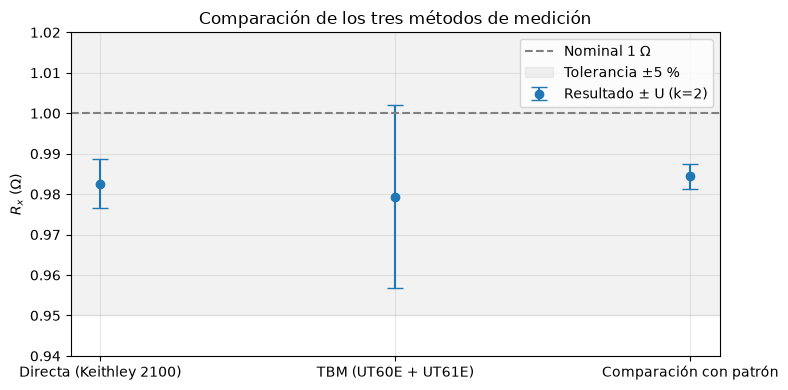

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(range(3), R_medias, yerr=U_metodos, fmt='o', capsize=6, color='tab:blue', label='Resultado ± U (k=2)')
ax.axhline(R_nominal, color='gray', linestyle='--', label='Nominal 1 Ω')
ax.axhspan(R_nominal * (1 - tolerancia / 100), R_nominal * (1 + tolerancia / 100), color='gray', alpha=0.1, label='Tolerancia ±5 %')
ax.set_xticks(range(3))
ax.set_xticklabels(metodos)
ax.set_ylabel('$R_x$ (Ω)')
ax.set_ylim(0.94, 1.02)
ax.set_title('Comparación de los tres métodos de medición')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

# Conclusiones

**Uso de los cuatro terminales.** En los tres métodos fue fundamental separar el camino de la corriente del de la tensión. Con una resistencia del orden de $1\,\Omega$, una resistencia de contacto o de cables de unas decenas de $\mathrm{m\Omega}$ ya produciría un error de varios por ciento, mayor que cualquiera de las incertidumbres obtenidas. Al soldar los terminales de tensión junto al cuerpo del resistor, las resistencias de contacto de los terminales de corriente y de los cables quedan fuera de la medición, y por las de los terminales de tensión prácticamente no circula corriente.

**Resultados obtenidos:**

| Método | $R_x$ ($\Omega$) | $U$ relativa |
|---|---|---|
| Directa (Keithley 2100, $\Omega$ 4 hilos) | $0{,}9826 \pm 0{,}0060$ | $0{,}61\,\%$ |
| TBM (UT60E + UT61E) | $0{,}979 \pm 0{,}023$ | $2{,}3\,\%$ |
| Comparación con patrón | $0{,}9843 \pm 0{,}0031$ | $0{,}31\,\%$ |

Los tres resultados son **compatibles entre sí** y se ubican entre un $1{,}6\,\%$ y un $2{,}1\,\%$ por debajo del valor nominal, dentro de la tolerancia del $5\,\%$ del resistor utilizado. Esto confirma que la resistencia construida vale aproximadamente $0{,}98\,\Omega$.

**Medición directa.** Es el método más práctico: una sola lectura, sin armar circuito ni hacer cálculos. Su incertidumbre está dominada por el término del $0{,}005\,\%$ del rango ($5\,\mathrm{m\Omega}$ en el rango de $100\,\Omega$), que es unas 30 veces mayor que el término de lectura ($\approx 0{,}15\,\mathrm{m\Omega}$), ya que se mide un valor 100 veces menor que el fondo de escala. Además, el display quedó configurado con una resolución de $1\,\mathrm{m\Omega}$, lo que desaprovecha los $6\tfrac{1}{2}$ dígitos del instrumento.

**Medición por TBM.** Es el método con mayor incertidumbre ($\approx 2{,}3\,\%$), casi 8 veces la de la comparación. Hay dos causas: intervienen dos instrumentos y sus errores se suman en forma cuadrática ($0{,}8\,\%$ del UT60E y $0{,}5\,\% + 10\ \text{d}$ del UT61E), y la tensión medida ($29{,}6\,\mathrm{mV}$ con resolución de $0{,}1\,\mathrm{mV}$) tiene solo tres cifras significativas, por lo que los dígitos pesan un $1\,\%$. El error de método por la corriente que deriva el voltímetro ($\approx 10^{-7}$) es despreciable. El resultado mejoraría inyectando más corriente (sin calentar la resistencia) o midiendo la tensión con el rango de $220\,\mathrm{mV}$ del UT61E, que tiene mejor resolución y exactitud.

**Medición por comparación.** Es el método con menor incertidumbre. Al circular la misma corriente por $R_x$ y $R_p$, la corriente desaparece de la ecuación de medición y no se necesita amperímetro. Además, como ambas tensiones se miden con el mismo voltímetro, en el mismo rango y con valores casi iguales, el error de ganancia del instrumento se cancela en el cociente $V_x/V_p$. Así, la exactitud del resultado queda determinada por la del patrón y por la resolución del voltímetro, y no por la clase del multímetro. Si se ignorara esta correlación, la incertidumbre crecería a $\approx 1{,}6\,\%$. Hay que tener en cuenta que el valor y la tolerancia del patrón ($1\,\Omega \pm 0{,}05\,\%$) son un supuesto, por lo que conocer su certificado de calibración permitiría afirmar este resultado con mayor fundamento.

En resumen, con el instrumental disponible el método de comparación es el más exacto, la medición directa es la más rápida con una incertidumbre aceptable, y el método TBM queda limitado por la clase y la resolución de los multímetros portátiles a tensiones tan bajas.